<a href="https://colab.research.google.com/github/sakshi56896ff/cfpb-bank-complaints-analysis/blob/main/cfpb_complaintsipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd, sqlite3

base = "/content/drive/MyDrive/cfpb-complaints/"
df = pd.read_csv(base + "complaints.csv")
print(df.shape)
print(df.columns.tolist())
print(df.isnull().sum())

conn = sqlite3.connect(base + "complaints.db")
df.to_sql("complaints", conn, if_exists="replace", index=False)

(42838, 15)
['Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Company public response', 'Company', 'State', 'ZIP code', 'Tags', 'Submitted via', 'Date sent to company', 'Company response to consumer', 'Timely response?', 'Complaint ID']
Date received                       0
Product                             0
Sub-product                         0
Issue                               0
Sub-issue                          38
Company public response         21897
Company                             0
State                             245
ZIP code                          180
Tags                            35742
Submitted via                       0
Date sent to company                0
Company response to consumer        0
Timely response?                    0
Complaint ID                        0
dtype: int64


42838

In [3]:
pd.read_sql("SELECT company, COUNT(*) AS total FROM complaints GROUP BY company ORDER BY total DESC", conn)

,Company,total
0,CAPITAL ONE FINANCIAL CORPORATION,13710
1,"CITIBANK, N.A.",12157
2,JPMORGAN CHASE & CO.,7201
3,"BANK OF AMERICA, NATIONAL ASSOCIATION",6147
4,WELLS FARGO & COMPANY,3623


In [4]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np, sqlite3
import matplotlib.pyplot as plt, seaborn as sns

base = "/content/drive/MyDrive/cfpb-complaints/"
raw = pd.read_csv(base + "complaints.csv")
print(raw.shape)
print(raw["Company response to consumer"].value_counts())
print(raw["Timely response?"].value_counts())
print(raw["Submitted via"].value_counts())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(42838, 15)
Company response to consumer
Closed with explanation            28921
Closed with monetary relief         8434
Closed with non-monetary relief     4116
In progress                         1361
Untimely response                      6
Name: count, dtype: int64
Timely response?
Yes    42790
No        48
Name: count, dtype: int64
Submitted via
Web            39001
Referral        2175
Phone           1151
Postal mail      511
Name: count, dtype: int64


In [5]:
BANK_MAP = {
    "CAPITAL ONE FINANCIAL CORPORATION": "Capital One",
    "CITIBANK, N.A.": "Citi",
    "JPMORGAN CHASE & CO.": "Chase",
    "BANK OF AMERICA, NATIONAL ASSOCIATION": "Bank of America",
    "WELLS FARGO & COMPANY": "Wells Fargo",
}
RELIEF = ["Closed with monetary relief", "Closed with non-monetary relief", "Closed with relief"]

def clean_data(df):
    df = df.copy()
    df.columns = (df.columns.str.strip().str.lower()
                  .str.replace("?", "", regex=False)
                  .str.replace("-", "_").str.replace(" ", "_"))
    for c in df.select_dtypes("object"):
        df[c] = df[c].str.strip()

    df = df.drop_duplicates(subset="complaint_id")

    df["date_received"] = pd.to_datetime(df["date_received"])
    df["date_sent_to_company"] = pd.to_datetime(df["date_sent_to_company"])
    df["month"] = df["date_received"].dt.strftime("%Y-%m")
    df["days_to_company"] = (df["date_sent_to_company"] - df["date_received"]).dt.days
    df["date_received"] = df["date_received"].dt.strftime("%Y-%m-%d")
    df["date_sent_to_company"] = df["date_sent_to_company"].dt.strftime("%Y-%m-%d")

    df["bank"] = df["company"].map(BANK_MAP).fillna(df["company"])
    df["state"] = df["state"].fillna("Unknown")
    df["zip_code"] = df["zip_code"].fillna("Unknown")
    df["sub_issue"] = df["sub_issue"].fillna("Not specified")
    df["company_public_response"] = df["company_public_response"].fillna("Not provided")
    df["tags"] = df["tags"].fillna("None")

    df["timely_flag"] = (df["timely_response"] == "Yes").astype(int)
    df["relief_flag"] = df["company_response_to_consumer"].isin(RELIEF).astype(int)
    return df

df = clean_data(raw)

print("Rows before:", len(raw), "| after:", len(df))
print("Duplicates removed:", len(raw) - len(df))
print("Nulls left:\n", df.isnull().sum()[df.isnull().sum() > 0])

conn = sqlite3.connect(base + "complaints.db")
raw_copy = raw.copy()
raw_copy.to_sql("complaints_raw", conn, if_exists="replace", index=False)
df.to_sql("complaints_clean", conn, if_exists="replace", index=False)
conn.execute("CREATE INDEX IF NOT EXISTS idx_bank ON complaints_clean(bank)")
conn.execute("CREATE INDEX IF NOT EXISTS idx_issue ON complaints_clean(issue)")
conn.commit()

Rows before: 42838 | after: 42838
Duplicates removed: 0
Nulls left:
 Series([], dtype: int64)


In [6]:
q = lambda sql: pd.read_sql(sql, conn)

# 1. Bank scorecard
by_bank = q("""
SELECT bank,
       COUNT(*) AS complaints,
       ROUND(100.0*COUNT(*)/(SELECT COUNT(*) FROM complaints_clean),1) AS pct_of_total,
       ROUND(100.0*AVG(timely_flag),1) AS timely_pct,
       ROUND(100.0*AVG(relief_flag),1) AS relief_pct
FROM complaints_clean GROUP BY bank ORDER BY complaints DESC""")
print(by_bank)

# 2. Top issues overall
top_issues = q("""
SELECT issue, COUNT(*) AS complaints,
       ROUND(100.0*COUNT(*)/(SELECT COUNT(*) FROM complaints_clean),1) AS pct_of_total,
       ROUND(100.0*AVG(relief_flag),1) AS relief_pct
FROM complaints_clean GROUP BY issue ORDER BY complaints DESC LIMIT 10""")
print(top_issues)

# 3. Monthly trend by bank
monthly = q("""
SELECT month, bank, COUNT(*) AS complaints
FROM complaints_clean GROUP BY month, bank ORDER BY month""")

# 4. Month-over-month change (window function: LAG)
mom = q("""
WITH m AS (SELECT month, COUNT(*) AS complaints FROM complaints_clean GROUP BY month)
SELECT month, complaints,
       LAG(complaints) OVER (ORDER BY month) AS prev_month,
       ROUND(100.0*(complaints - LAG(complaints) OVER (ORDER BY month))
             / LAG(complaints) OVER (ORDER BY month),1) AS mom_change_pct
FROM m""")
print(mom)

# 5. Top 3 issues inside each bank (window function: RANK)
issue_rank = q("""
SELECT * FROM (
  SELECT bank, issue, COUNT(*) AS complaints,
         RANK() OVER (PARTITION BY bank ORDER BY COUNT(*) DESC) AS rnk
  FROM complaints_clean GROUP BY bank, issue
) WHERE rnk <= 3 ORDER BY bank, rnk""")
print(issue_rank)

# 6. Issues with the lowest relief rate (minimum volume 200)
low_relief = q("""
SELECT issue, COUNT(*) AS complaints,
       ROUND(100.0*AVG(relief_flag),1) AS relief_pct
FROM complaints_clean GROUP BY issue
HAVING COUNT(*) >= 200 ORDER BY relief_pct ASC LIMIT 10""")
print(low_relief)

# 7. Citi vs the other four banks: issue share
citi_vs_peers = q("""
WITH t AS (
  SELECT issue,
         SUM(CASE WHEN bank='Citi' THEN 1 ELSE 0 END) AS citi_n,
         SUM(CASE WHEN bank!='Citi' THEN 1 ELSE 0 END) AS peers_n
  FROM complaints_clean GROUP BY issue)
SELECT issue,
       ROUND(100.0*citi_n/(SELECT SUM(citi_n) FROM t),1) AS citi_share_pct,
       ROUND(100.0*peers_n/(SELECT SUM(peers_n) FROM t),1) AS peers_share_pct
FROM t ORDER BY citi_n DESC LIMIT 10""")
print(citi_vs_peers)

# 8. Channel and state
channel = q("""SELECT submitted_via, COUNT(*) AS complaints
FROM complaints_clean GROUP BY submitted_via ORDER BY complaints DESC""")
states = q("""SELECT state, COUNT(*) AS complaints FROM complaints_clean
WHERE state!='Unknown' GROUP BY state ORDER BY complaints DESC LIMIT 10""")

# 9. Complaints involving older Americans or servicemembers
tags = q("""SELECT tags, COUNT(*) AS complaints,
ROUND(100.0*AVG(relief_flag),1) AS relief_pct
FROM complaints_clean GROUP BY tags ORDER BY complaints DESC""")
print(tags)

# A. What is inside the biggest issue? (sub-issue breakdown)
sub = q("""
SELECT sub_issue, COUNT(*) AS complaints,
       ROUND(100.0*COUNT(*)/(SELECT COUNT(*) FROM complaints_clean
            WHERE issue='Problem with a purchase shown on your statement'),1) AS pct_within_issue,
       ROUND(100.0*AVG(relief_flag),1) AS relief_pct
FROM complaints_clean
WHERE issue='Problem with a purchase shown on your statement'
GROUP BY sub_issue ORDER BY complaints DESC LIMIT 10""")
print(sub)

# B. Relief rate by bank for the top 5 issues
bank_issue_relief = q("""
SELECT bank, issue, COUNT(*) AS complaints,
       ROUND(100.0*AVG(relief_flag),1) AS relief_pct
FROM complaints_clean
WHERE issue IN (SELECT issue FROM complaints_clean GROUP BY issue ORDER BY COUNT(*) DESC LIMIT 5)
GROUP BY bank, issue ORDER BY issue, relief_pct DESC""")
print(bank_issue_relief)

# C. How do responses break down by bank?
resp = q("""
SELECT bank, company_response_to_consumer, COUNT(*) AS n,
       ROUND(100.0*COUNT(*)/SUM(COUNT(*)) OVER (PARTITION BY bank),1) AS pct_of_bank
FROM complaints_clean GROUP BY bank, company_response_to_consumer
ORDER BY bank, n DESC""")
print(resp)


              bank  complaints  pct_of_total  timely_pct  relief_pct
0      Capital One       13710          32.0       100.0        21.0
1             Citi       12157          28.4       100.0        42.0
2            Chase        7201          16.8       100.0        19.9
3  Bank of America        6147          14.3        99.3        35.8
4      Wells Fargo        3623           8.5       100.0        25.7
                                               issue  complaints  \
0    Problem with a purchase shown on your statement       15681   
1                 Other features, terms, or problems        5896   
2                                   Fees or interest        3773   
3                              Getting a credit card        3684   
4                               Closing your account        3222   
5               Incorrect information on your report        2234   
6                       Problem when making payments        2223   
7  Advertising and marketing, including pr

In [7]:
START, END = "2025-11", "2026-09"   # complete months only

monthly_full = monthly[(monthly["month"] >= START) & (monthly["month"] <= END)]

mom_full = q(f"""
WITH m AS (
  SELECT month, COUNT(*) AS complaints
  FROM complaints_clean
  WHERE month BETWEEN '{START}' AND '{END}'
  GROUP BY month)
SELECT month, complaints,
       LAG(complaints) OVER (ORDER BY month) AS prev_month,
       ROUND(100.0*(complaints - LAG(complaints) OVER (ORDER BY month))
             / LAG(complaints) OVER (ORDER BY month),1) AS mom_change_pct
FROM m""")
print(mom_full)

      month  complaints  prev_month  mom_change_pct
0   2025-11        2735         NaN             NaN
1   2025-12        3426      2735.0            25.3
2   2026-01        3834      3426.0            11.9
3   2026-02        3191      3834.0           -16.8
4   2026-03        3647      3191.0            14.3
5   2026-04        3882      3647.0             6.4
6   2026-05        3712      3882.0            -4.4
7   2026-06        3628      3712.0            -2.3
8   2026-07        3885      3628.0             7.1
9   2026-08        4110      3885.0             5.8
10  2026-09        4392      4110.0             6.9


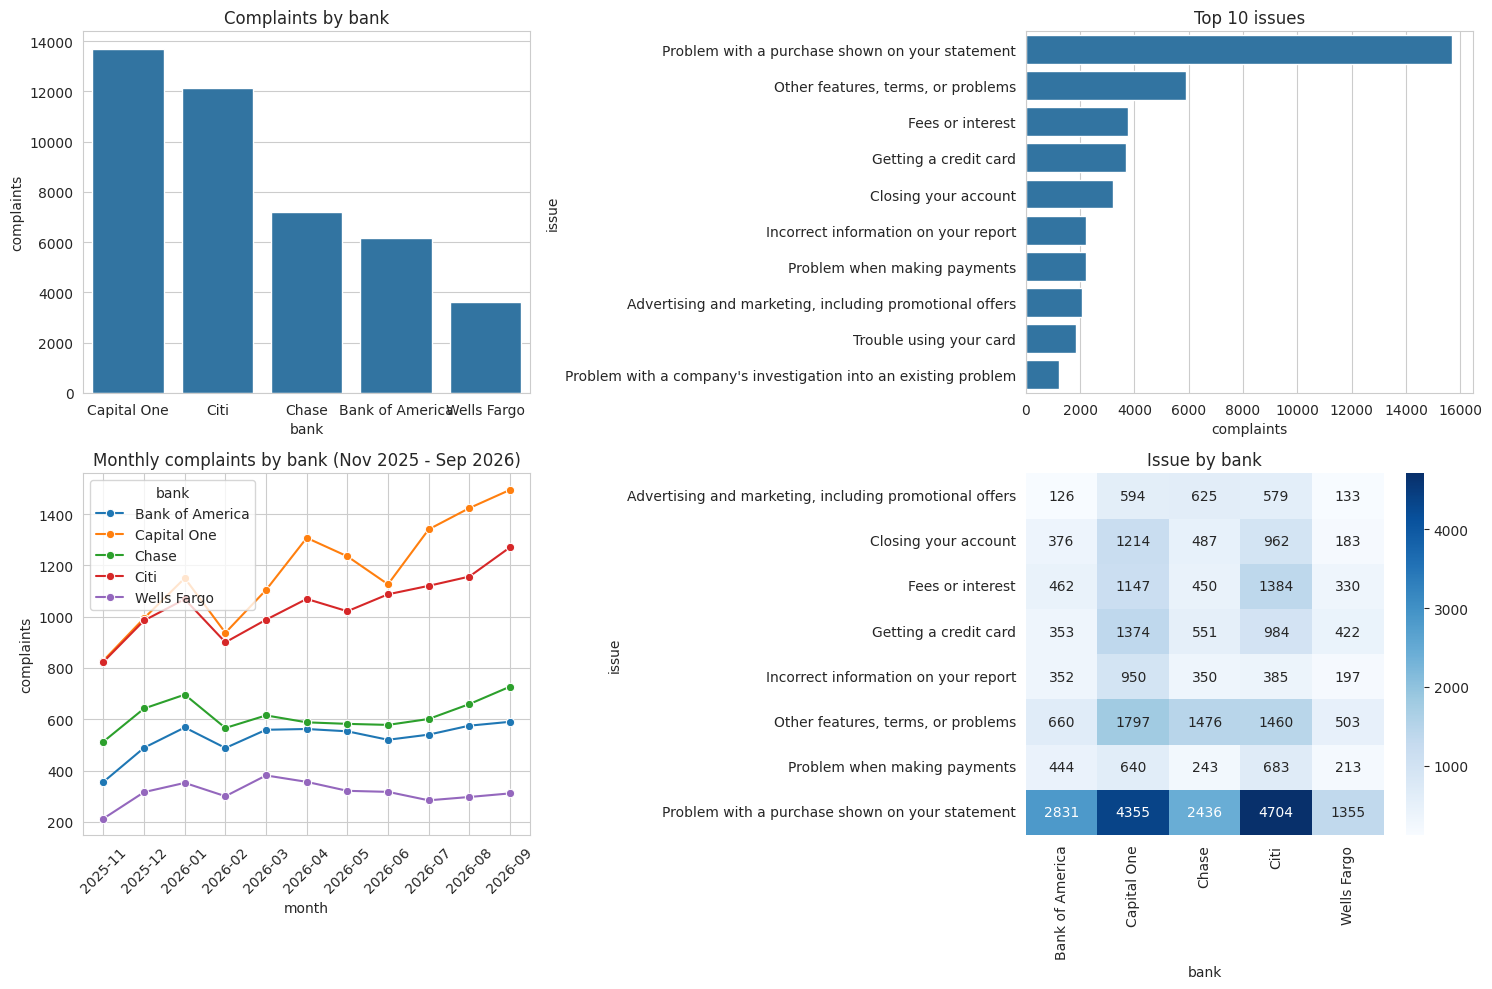

In [8]:
sns.set_style("whitegrid")
fig, ax = plt.subplots(2, 2, figsize=(15, 10))

sns.barplot(data=by_bank, x="bank", y="complaints", ax=ax[0,0])
ax[0,0].set_title("Complaints by bank")

sns.barplot(data=top_issues, y="issue", x="complaints", ax=ax[0,1])
ax[0,1].set_title("Top 10 issues")

sns.lineplot(data=monthly_full, x="month", y="complaints", hue="bank", marker="o", ax=ax[1,0])
ax[1,0].set_title("Monthly complaints by bank (Nov 2025 - Sep 2026)")
ax[1,0].tick_params(axis="x", rotation=45)

heat = q("""SELECT bank, issue, COUNT(*) AS n FROM complaints_clean
WHERE issue IN (SELECT issue FROM complaints_clean GROUP BY issue ORDER BY COUNT(*) DESC LIMIT 8)
GROUP BY bank, issue""").pivot(index="issue", columns="bank", values="n").fillna(0)
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Blues", ax=ax[1,1])
ax[1,1].set_title("Issue by bank")

plt.tight_layout()
plt.savefig(base + "overview.png", dpi=150)
plt.show()

In [9]:
out = base + "dashboard_data/"
import os; os.makedirs(out, exist_ok=True)


df.to_csv(out + "complaints_clean.csv", index=False)
by_bank.to_csv(out + "by_bank.csv", index=False)
monthly_full.to_csv(out + "monthly.csv", index=False)
mom_full.to_csv(out + "mom.csv", index=False)

In [10]:
def run_pipeline(csv_path, out_xlsx):
    d = clean_data(pd.read_csv(csv_path))
    summary = {
        "by_bank": d.groupby("bank").agg(complaints=("complaint_id","count"),
                    timely_pct=("timely_flag", lambda s: round(100*s.mean(),1)),
                    relief_pct=("relief_flag", lambda s: round(100*s.mean(),1))).reset_index(),
        "top_issues": d["issue"].value_counts().head(15).rename_axis("issue").reset_index(name="complaints"),
        "monthly": d[(d["month"] >= START) & (d["month"] <= END)]
            .groupby(["month","bank"]).size().reset_index(name="complaints"),
        "issue_by_bank": pd.crosstab(d["issue"], d["bank"]),
    }
    with pd.ExcelWriter(out_xlsx) as w:
        for name, t in summary.items():
            t.to_excel(w, sheet_name=name, index=(name == "issue_by_bank"))
    return d, summary

_ = run_pipeline(base + "complaints.csv", base + "weekly_summary.xlsx")
print("Report generated")

Report generated


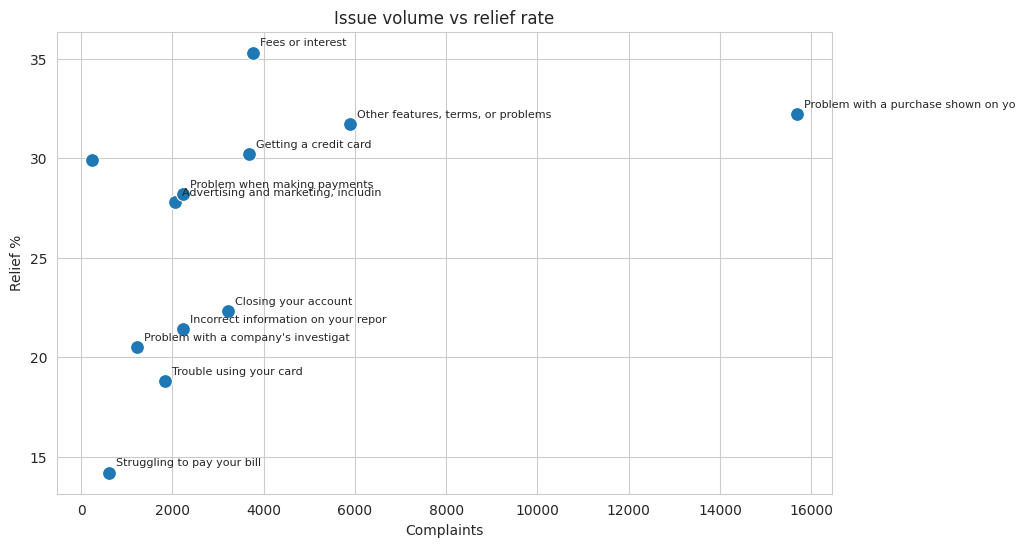

company_response_to_consumer
Closed with explanation            23
Closed with monetary relief        18
Untimely response                   6
Closed with non-monetary relief     1
Name: count, dtype: int64


In [11]:
out = base + "dashboard_data/"
bank_issue_relief.to_csv(out + "bank_issue_relief.csv", index=False)
resp.to_csv(out + "response_by_bank.csv", index=False)
citi_vs_peers.to_csv(out + "citi_vs_peers.csv", index=False)
issue_rank.to_csv(out + "top3_issues_by_bank.csv", index=False)

# Relief gap chart: big issues with low relief are the priorities
gap = q("""SELECT issue, COUNT(*) AS complaints,
           ROUND(100.0*AVG(relief_flag),1) AS relief_pct
           FROM complaints_clean GROUP BY issue HAVING COUNT(*) >= 200""")
plt.figure(figsize=(10, 6))
sns.scatterplot(data=gap, x="complaints", y="relief_pct", s=100)
for _, r in gap.iterrows():
    if r["complaints"] > 1800 or r["relief_pct"] < 21:
        plt.annotate(r["issue"][:35], (r["complaints"], r["relief_pct"]),
                     fontsize=8, xytext=(5, 5), textcoords="offset points")
plt.title("Issue volume vs relief rate")
plt.xlabel("Complaints"); plt.ylabel("Relief %")
plt.savefig(base + "relief_gap.png", dpi=150, bbox_inches="tight")
plt.show()

# Check what the "Timely response? = No" rows are
print(df[df["timely_response"] == "No"]["company_response_to_consumer"].value_counts())

In [12]:
   out = base + "dashboard_data/"
   citi_vs_peers.to_csv(out + "citi_vs_peers.csv", index=False)
   issue_rank.to_csv(out + "top3_issues_by_bank.csv", index=False)

In [13]:
print(df["timely_response"].value_counts())
print(df[df["timely_response"] == "No"]["company_response_to_consumer"].value_counts())

timely_response
Yes    42790
No        48
Name: count, dtype: int64
company_response_to_consumer
Closed with explanation            23
Closed with monetary relief        18
Untimely response                   6
Closed with non-monetary relief     1
Name: count, dtype: int64
